# 02 · Temporal Partitioning and Feature Engineering

Chronological partitions separate model fitting, configuration selection, probability calibration
and final evaluation. Feature transformations preserve this ordering: category vocabularies,
frequency estimates and constant-feature decisions depend only on the corresponding fitting data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src" / "fraud_detection").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from fraud_detection.config import Config
from fraud_detection.data import ID, TARGET, TIME

config = Config.load(ROOT / "configs" / "default.yaml")
processed_dir = Path(config.processed_dir)
artifact_dir = Path(config.output_dir)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})

In [3]:
%matplotlib inline

## 1. Chronological Evaluation Design

Training fits candidate models; tuning selects parameters and boosting iterations; calibration estimates
the probability mapping and review threshold. The holdout period measures final performance.
Partition boundaries follow complete relative days, so no day is shared between partitions.

,rows,first_day,last_day,fraud_rate
partition,,,,
train,356216,1,101,0.033797
tuning,88957,102,130,0.040368
calibration,59937,131,152,0.034019
holdout,85430,153,182,0.035046


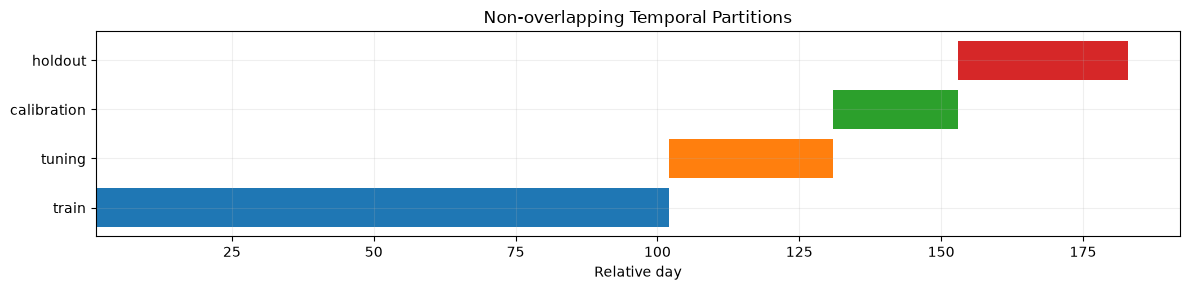

In [4]:
from fraud_detection.split import chronological_split

timeline = pd.read_parquet(processed_dir / "train.parquet", columns=[ID, TIME, TARGET])
timeline = timeline.sort_values([TIME, ID]).reset_index(drop=True)
partitions = chronological_split(timeline, config)
split_rows = []
for name, positions in partitions.items():
    subset = timeline.iloc[positions]
    split_rows.append(
        {
            "partition": name,
            "rows": len(subset),
            "first_day": int(subset[TIME].min() // 86400),
            "last_day": int(subset[TIME].max() // 86400),
            "fraud_rate": float(subset[TARGET].mean()),
        }
    )
splits = pd.DataFrame(split_rows).set_index("partition")
assert splits.rows.sum() == len(timeline)
assert (splits.first_day.iloc[1:].to_numpy() > splits.last_day.iloc[:-1].to_numpy()).all()
display(splits)

fig, ax = plt.subplots(figsize=(12, 3))
for name, row in splits.iterrows():
    ax.barh(name, row.last_day - row.first_day + 1, left=row.first_day)
ax.set(title="Non-overlapping Temporal Partitions", xlabel="Relative day")
plt.tight_layout()
plt.show()

## 2. Transaction-Level Features

TransactionID, the target and absolute TransactionDT are excluded from predictors.
Derived attributes describe missingness, relative hour and weekday, log amount, fractional amount
and email-domain agreement. Frequency estimates are fixed from the fitting period before later transactions are scored.

In [5]:
import pyarrow.parquet as pq

from fraud_detection.features import FeatureBuilder, engineer

first_batch = next(pq.ParquetFile(processed_dir / "train.parquet").iter_batches(batch_size=3000))
train_sample = first_batch.to_pandas().sort_values([TIME, ID]).reset_index(drop=True)
holdout_start = int(splits.loc["holdout", "first_day"]) * 86400
future_sample = (
    pd.read_parquet(
        processed_dir / "train.parquet",
        filters=[(TIME, ">=", holdout_start), (TIME, "<", holdout_start + 86400)],
    )
    .head(2000)
    .copy()
)
engineered = engineer(train_sample)
new_columns = [column for column in engineered if column not in train_sample]
display(engineered[["TransactionAmt", *new_columns]].head(10))

,TransactionAmt,missing_count,relative_hour,relative_weekday,amount_log1p,amount_cents,email_match
0,68.5,234.0,0.0,1.0,4.241327,50.0,0.0
1,29.0,230.0,0.0,1.0,3.401197,0.0,0.0
2,59.0,211.0,0.0,1.0,4.094345,0.0,0.0
3,50.0,227.0,0.0,1.0,3.931826,0.0,0.0
4,50.0,137.0,0.0,1.0,3.931826,0.0,0.0
5,49.0,214.0,0.0,1.0,3.912023,0.0,0.0
6,159.0,211.0,0.0,1.0,5.075174,0.0,0.0
7,422.5,230.0,0.0,1.0,6.048553,50.0,0.0
8,15.0,134.0,0.0,1.0,2.772589,0.0,0.0
9,117.0,211.0,0.0,1.0,4.770685,0.0,0.0


## 3. Fitted Preprocessing

A 3,000-row training sample exposes the feature builder's behavior without loading the entire feature matrix.
This sample transformer is distinct from the production transformer, which is refitted on training plus tuning
after parameter selection. Both apply the same transformation logic.

In [6]:
builder = FeatureBuilder()
train_features = builder.fit_transform(train_sample)
future_features = builder.transform(future_sample)
assert train_features.columns.equals(future_features.columns)
assert not {ID, TARGET, TIME}.intersection(train_features.columns)
display(
    pd.Series(
        {
            "demo_fit_rows": len(train_sample),
            "demo_future_rows": len(future_sample),
            "features": len(train_features.columns),
            "categorical": len(builder.categories_),
            "frequency_encoded": len(builder.frequencies_),
        }
    )
)
display(train_features.head())

demo_fit_rows        3000
demo_future_rows     2000
features              438
categorical            49
frequency_encoded       5
dtype: int64

,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,...,missing_count,relative_hour,amount_log1p,amount_cents,email_match,card1_frequency,card2_frequency,addr1_frequency,P_emaildomain_frequency,DeviceInfo_frequency
0,68.5,w,13926.0,__MISSING__,150.0,discover,142.0,credit,315.0,87.0,...,234.0,0.0,4.241327,50.0,0.0,0.000333,0.017000,0.050333,0.224667,0.829667
1,29.0,w,2755.0,404.0,150.0,mastercard,102.0,credit,325.0,87.0,...,230.0,0.0,3.401197,0.0,0.0,0.001000,0.003000,0.077333,0.347000,0.829667
2,59.0,w,4663.0,490.0,150.0,visa,166.0,debit,330.0,87.0,...,211.0,0.0,4.094345,0.0,0.0,0.002000,0.062000,0.049000,0.007667,0.829667
3,50.0,w,18132.0,567.0,150.0,mastercard,117.0,debit,476.0,87.0,...,227.0,0.0,3.931826,0.0,0.0,0.012000,0.014667,0.021667,0.181667,0.829667
4,50.0,h,4497.0,514.0,150.0,mastercard,102.0,credit,420.0,87.0,...,137.0,0.0,3.931826,0.0,0.0,0.000333,0.020333,0.006333,0.347000,0.000333


## 4. Unseen Categories and Target Independence

Categories absent from the fitted vocabulary become missing categorical values, while their frequency encoding is zero.
Altering target labels leaves the feature matrix unchanged because these transformations do not consume label statistics.

In [7]:
unseen = future_sample.head(5).copy()
unseen["card1"] = 999999
unseen["ProductCD"] = "UNSEEN_PRODUCT"
unseen_features = builder.transform(unseen)
assert unseen_features.card1.isna().all()
assert unseen_features.ProductCD.isna().all()
assert unseen_features.card1_frequency.eq(0).all()
display(unseen_features[["card1", "ProductCD", "card1_frequency"]])

changed_labels = train_sample.copy()
changed_labels[TARGET] = 1 - changed_labels[TARGET]
pd.testing.assert_frame_equal(train_features, builder.transform(changed_labels))
display(pd.Series({"target_independence": True, "unseen_categories_handled": True}))

,card1,ProductCD,card1_frequency
0,NaN,NaN,0.0
1,NaN,NaN,0.0
2,NaN,NaN,0.0
3,NaN,NaN,0.0
4,NaN,NaN,0.0


target_independence          True
unseen_categories_handled    True
dtype: bool

## 5. Model Feature Schema

The saved model contains the vocabulary and frequency mappings from its fitting period.
Its transformed column count must match the classifier's expected feature count;
vocabulary sizes reveal the cardinality of categorical predictors.

In [8]:
import joblib

saved_model = joblib.load(artifact_dir / "model.joblib")
saved_features = saved_model.features.transform(future_sample)
display(
    pd.Series(
        {
            "model_features": saved_model.classifier.n_features_in_,
            "transformed_features": saved_features.shape[1],
            "category_columns": len(saved_model.features.categories_),
            "threshold": saved_model.threshold,
        }
    )
)
assert saved_features.shape[1] == saved_model.classifier.n_features_in_
display(
    pd.DataFrame(
        [
            {"column": column, "vocabulary_size": len(values)}
            for column, values in saved_model.features.categories_.items()
        ]
    )
    .sort_values("vocabulary_size", ascending=False)
    .head(12)
)

model_features          442.000000
transformed_features    442.000000
category_columns         49.000000
threshold                 0.683876
dtype: float64

,column,vocabulary_size
1,card1,12504
48,DeviceInfo,1584
27,id_19,508
2,card2,501
29,id_21,437
28,id_20,372
7,addr1,322
33,id_25,312
41,id_33,199
5,card5,112


## Leakage Boundaries

Calibration, holdout and unlabeled test observations do not contribute to fitted feature mappings.
Full-period fraud-rate summaries remain descriptive, and the review threshold is selected before holdout evaluation.
These boundaries distinguish reusable preprocessing from retrospective analysis.